# Whisper hallucination space projection

Re-implementation of Abbasihafshejani & Jadliwala (2026), arXiv:2609.04561, plus our extra experiments.
Settings come from environment variables (`HALLU_MODEL`, `HALLU_FULL`, `HALLU_SMOKE`, `HALLU_DATA`, `HALLU_RESULTS`, `HALLU_BS`).
Every result is saved under `results/<model>/`; finished steps are loaded from there when the notebook is re-run.

## 1. Setup

In [1]:
import os, json, math, copy, random, platform, contextlib, collections, csv, time, warnings
from pathlib import Path
from dataclasses import dataclass, replace, asdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
pd.set_option("future.infer_string", False)   # pyarrow string columns crash this Python 3.14 kernel
import torch
import whisper
import jiwer
import soundfile as sf
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
from scipy.stats import rankdata, binomtest
from tqdm.auto import tqdm
from whisper.normalizers import EnglishTextNormalizer
from whisper.tokenizer import get_tokenizer
from whisper.model import ModelDimensions, Whisper
try:
    from IPython.display import display
except ImportError:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

warnings.filterwarnings("ignore")
T0 = time.time()

MODEL_NAME  = os.environ.get("HALLU_MODEL", "small")         # small | medium | large-v3
SMOKE       = os.environ.get("HALLU_SMOKE", "0") == "1"       # tiny random model, tiny subsets: pipeline check only
FULL        = os.environ.get("HALLU_FULL", "0") == "1"        # full test sets instead of seeded subsets
DATA_ROOT   = Path(os.environ.get("HALLU_DATA", "data"))
RESULTS_DIR = Path(os.environ.get("HALLU_RESULTS", f"results/{'smoke' if SMOKE else MODEL_NAME}"))
BATCH_SIZE  = int(os.environ.get("HALLU_BS", 16))             # keep fixed across runs: fp16 results depend slightly on it
SEED = 0

LIMITS = dict(calib=None, sweep_ns=400, sweep_speech=200, esc50_test=None, urban=2000, fsd=2000, test_clean=1000, test_other=1000)
if FULL:
    LIMITS.update(sweep_ns=None, sweep_speech=300, urban=None, fsd=None, test_clean=None, test_other=None)
if SMOKE:
    LIMITS = dict(calib=40, sweep_ns=20, sweep_speech=8, esc50_test=12, urban=12, fsd=12, test_clean=8, test_other=8)

SWEEP_RANKS  = [1, 2, 4, 8]
SWEEP_ALPHAS = [0.25, 0.5, 0.75, 1.0]
SWEEP_GAMMAS = [0.03, 0.05, 0.10, 0.15]
WER_TOL_PP   = 0.5                       # a setting is acceptable if dev WER <= plain Whisper + this
TAU          = 0.6                       # Whisper's default no-speech threshold
TAU_FINE     = [round(t, 2) for t in np.arange(0.02, 0.605, 0.01)]
FSD_EXCLUDE  = {"Speech", "Human_voice"}  # 8,598 eval clips (paper: 8,621); removing music too would leave 6,729
CKPT_EVERY_S = 90

torch.set_grad_enabled(False)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FP16 = DEVICE == "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

SW, EVAL, TAB, FIG, CKPT = (RESULTS_DIR / d for d in ("sweeps", "eval", "tables", "figures", "checkpoints"))
for d in (RESULTS_DIR / "calibration", SW, EVAL, TAB, FIG, CKPT):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 120,
                     "savefig.dpi": 300, "savefig.bbox": "tight"})

def save_table(df, name, show=True):
    df.to_csv(TAB / f"{name}.csv")
    if show:
        display(df.round(2) if hasattr(df, "round") else df)

def save_fig(name):
    plt.savefig(FIG / f"{name}.png")
    plt.show()

print(f"device={DEVICE} fp16={FP16} torch={torch.__version__} whisper={whisper.__version__} smoke={SMOKE}")
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("data:", DATA_ROOT.resolve(), "| results:", RESULTS_DIR.resolve())

device=cuda fp16=True torch=2.11.0+cu128 whisper=20250625 smoke=False
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
data: E:\Speech And Audio Processing Project\whisper-halluspace\data | results: E:\Speech And Audio Processing Project\whisper-halluspace\results\small


## 2. Core: projection hook, basis, decoding engine

In [2]:
@torch.no_grad()
def first_step(model, feats, tokenizer, capture=False):
    """No-speech probability at the SOT position of the first decoding step (what whisper.decode reports).
    capture=True also returns the SOT state after every decoder block: [batch, layers, d]."""
    prompt = torch.tensor([tokenizer.sot_sequence_including_notimestamps], device=feats.device).repeat(len(feats), 1)
    states, hooks = [], []
    if capture:
        hooks = [b.register_forward_hook(lambda _m, _i, out: states.append(out[:, 0].float().cpu()))
                 for b in model.decoder.blocks]
    try:
        logits = model.decoder(prompt, feats)
    finally:
        for h in hooks:
            h.remove()
    p_ns = logits[:, 0].float().softmax(-1)[:, tokenizer.no_speech].cpu()
    return (p_ns, torch.stack(states, 1)) if capture else p_ns


@contextlib.contextmanager
def project(model, layer, basis, alpha=1.0, center=None):
    """Edit the output of decoder block `layer` (1-indexed): h <- h - alpha * ((h - c) B^T) B.
    center=None is the paper's Eq. (1) (c = 0); the affine variant uses c = mean state of the correctly-empty clips."""
    block = model.decoder.blocks[layer - 1]
    dev = next(block.parameters()).device
    B = basis.to(dev).float()
    c = None if center is None else center.to(dev).float()

    def hook(_m, _i, out):
        x = out.float()                                   # arithmetic in fp32, result back in the activation dtype
        coord = (x if c is None else x - c) @ B.T
        return (x - alpha * coord @ B).to(out.dtype)

    handle = block.register_forward_hook(hook)
    try:
        yield
    finally:
        handle.remove()


def half_weights(model):
    """Cast Linear/Conv/Embedding weights to fp16 once (Whisper otherwise casts them on every call); LayerNorms stay fp32."""
    from whisper.model import Linear, Conv1d
    for m in model.modules():
        if isinstance(m, (Linear, Conv1d, torch.nn.Embedding)):
            m.half()
    return model


def fit_basis(H, F, rank):
    """Paper Sec. 3.2: rows of Delta are h_hall_i - h_empty_i (paired in order, n = min(Nh, Nf));
    B = top-`rank` right singular vectors of Delta, shape [rank, d] with orthonormal rows."""
    if len(H) == 0 or len(F) == 0:
        raise ValueError(f"need both classes, got {len(H)} hallucinated / {len(F)} empty clips")
    n = min(len(H), len(F))
    delta = H[:n].double() - F[:n].double()
    return torch.linalg.svd(delta, full_matrices=False).Vh[:rank].float()


@dataclass(frozen=True)
class ProjConfig:
    layer: int
    rank: int
    alpha: float
    gamma: float
    tau: float = TAU

PAPER_CONFIGS = {   # paper Sec. 5.1 / Appendix C
    "small":    ProjConfig(layer=10, rank=1, alpha=1.0,  gamma=0.15),
    "medium":   ProjConfig(layer=24, rank=2, alpha=0.75, gamma=0.10),
    "large-v3": ProjConfig(layer=28, rank=4, alpha=1.0,  gamma=0.05),
}


@dataclass
class Result:
    text: str          # final transcript ("" if rejected)
    raw_text: str      # decoded text before the no-speech filter ("" if not decoded)
    p_ns_base: float   # unprojected no-speech probability (gate input)
    p_ns: float        # no-speech probability used for the decision
    projected: bool
    rejected: bool     # p_ns > tau


class BatchCache:
    """First-step p_ns and decoded texts of one batch for each projection setting (key None = no projection),
    shared by all engines so no (setting, clip) pair is decoded twice."""
    def __init__(self, model, tok, opts, feats, p_base):
        self.model, self.tok, self.opts, self.feats = model, tok, opts, feats
        self.p, self.txt = {None: p_base}, {None: {}}

    def _ctx(self, eng, key):
        if key is None:
            return contextlib.nullcontext()
        return project(self.model, eng.cfg.layer, eng.basis, eng.cfg.alpha, eng.center)

    def p_ns(self, eng, key):
        if key not in self.p:
            with self._ctx(eng, key):
                self.p[key] = first_step(self.model, self.feats, self.tok)
            self.txt[key] = {}
        return self.p[key]

    def texts(self, eng, key, idx):
        need = [i for i in idx if i not in self.txt[key]]
        if need:
            with self._ctx(eng, key):
                for i, r in zip(need, whisper.decode(self.model, self.feats[need], self.opts)):
                    self.txt[key][i] = r.text.strip()
        return [self.txt[key][i] for i in idx]


class Engine:
    """Algorithm 1. mode: original | always | gated | gate_only.
    gate_only rejects every clip with p_ns_base >= gamma and never projects (ablation).
    keep_raw=False skips decoding clips that are rejected anyway (same metrics, faster);
    keep_raw=True decodes everything so other thresholds can be scored later."""
    MODES = ("original", "always", "gated", "gate_only")

    def __init__(self, mode, cfg, basis=None, center=None, keep_raw=False):
        assert mode in self.MODES, mode
        self.mode, self.cfg, self.basis, self.center, self.keep_raw = mode, cfg, basis, center, keep_raw

    @property
    def key(self):
        return (self.cfg.layer, id(self.basis), self.cfg.alpha, id(self.center))

    def signature(self):
        s = lambda t: None if t is None else round(float(t.abs().sum()), 4)
        return repr((self.mode, self.cfg, self.keep_raw, s(self.basis), s(self.center)))

    def gate(self, p_base):
        if self.mode == "original":
            return torch.zeros(len(p_base), dtype=torch.bool)
        if self.mode == "always":
            return torch.ones(len(p_base), dtype=torch.bool)
        return p_base >= self.cfg.gamma

    def decode_batch(self, cache):
        # Decoding each clip once, with or without the hook, equals the paper's "decode, then re-decode if gated":
        # p_ns_base is fixed by the first decoder step alone.
        p_base = cache.p[None]
        gate = self.gate(p_base)
        out = [None] * len(p_base)
        for flag in (False, True):
            idx = torch.nonzero(gate == flag).flatten().tolist()
            if not idx:
                continue
            if flag and self.mode == "gate_only":
                for i in idx:
                    p = float(p_base[i])
                    out[i] = Result("", "", p, p, False, True)
                continue
            key = self.key if flag else None
            p = cache.p_ns(self, key)
            todo = idx if self.keep_raw else [i for i in idx if float(p[i]) <= self.cfg.tau]
            raw = dict(zip(todo, cache.texts(self, key, todo)))
            for i in idx:
                rejected = float(p[i]) > self.cfg.tau
                txt = raw.get(i, "")
                out[i] = Result("" if rejected else txt, txt, float(p_base[i]), float(p[i]), flag, rejected)
        return out

## 3. Sanity tests (tiny random Whisper)

In [3]:
def tiny_model(device="cpu"):
    dims = ModelDimensions(n_mels=80, n_audio_ctx=1500, n_audio_state=64, n_audio_head=4, n_audio_layer=2,
                           n_vocab=51865, n_text_ctx=448, n_text_state=64, n_text_head=4, n_text_layer=4)
    torch.manual_seed(0)
    m = Whisper(dims).eval().requires_grad_(False)
    torch.nn.init.normal_(m.decoder.positional_embedding, std=0.02)   # Whisper leaves it uninitialised
    return m.to(device)


def run_sanity_tests():
    m = tiny_model()
    tk = get_tokenizer(m.is_multilingual, num_languages=m.num_languages, language="en", task="transcribe")
    op = whisper.DecodingOptions(language="en", without_timestamps=True, fp16=False, sample_len=6)
    feats = m.embed_audio(torch.randn(3, 80, 3000))

    B = fit_basis(torch.randn(30, 64) + 2, torch.randn(50, 64), rank=4)
    assert torch.allclose(B @ B.T, torch.eye(4), atol=1e-5), "basis not orthonormal"

    def block_out(layer=3):
        seen = []
        h = m.decoder.blocks[layer - 1].register_forward_hook(lambda _m, _i, o: seen.append(o.clone()))
        first_step(m, feats, tk)
        h.remove()
        return seen[0]

    B2, c = fit_basis(torch.randn(20, 64) + 1, torch.randn(20, 64), rank=2), torch.randn(64)
    h = block_out()
    tol = 1e-4 * max(1.0, h.abs().max().item())
    for alpha in (1.0, 0.5):
        with project(m, 3, B2, alpha):
            h2 = block_out()
        assert torch.allclose(h2 @ B2.T, (1 - alpha) * (h @ B2.T), atol=tol, rtol=1e-3), "in-subspace part wrong"
        resid = (h2 - h) - ((h2 - h) @ B2.T) @ B2
        assert resid.abs().max() < tol, "projection changed other directions"
    with project(m, 3, B2, 1.0, center=c):
        h3 = block_out()
    assert torch.allclose(h3 @ B2.T, (c @ B2.T).expand_as(h3 @ B2.T), atol=tol), "affine edit does not move to the center"
    assert torch.allclose(block_out(), h), "hook not removed"

    p = first_step(m, feats, tk)
    dec = whisper.decode(m, feats, op)
    assert torch.allclose(p, torch.tensor([r.no_speech_prob for r in dec]), atol=1e-6), "first_step != decode"
    with project(m, 3, B2):
        pp, dp = first_step(m, feats, tk), whisper.decode(m, feats, op)
    assert torch.allclose(pp, torch.tensor([r.no_speech_prob for r in dp]), atol=1e-6), "projected first_step != decode"

    cfg = ProjConfig(layer=3, rank=2, alpha=1.0, gamma=0.0)
    run = lambda eng, cache=None: eng.decode_batch(cache or BatchCache(m, tk, op, feats, p))
    orig = run(Engine("original", cfg, keep_raw=True))
    assert [r.raw_text for r in orig] == [r.text.strip() for r in dec], "engine text != whisper.decode"
    noop = run(Engine("always", replace(cfg, alpha=0.0), B2, keep_raw=True))
    assert [r.raw_text for r in orig] == [r.raw_text for r in noop], "alpha = 0 must be a no-op"
    assert all(r.projected for r in run(Engine("always", cfg, B2)))
    g = sorted(p.tolist())[1]
    gated = run(Engine("gated", replace(cfg, gamma=g), B2))
    assert [r.projected for r in gated] == [x >= g for x in p.tolist()], "gate decision wrong"
    assert all(r.rejected for r in run(Engine("gate_only", cfg))), "gate_only with gamma = 0 must reject all"
    assert all(r.rejected and r.text == "" for r in run(Engine("original", replace(cfg, tau=0.0))))

    for tau in (0.0, float(sorted(pp.tolist())[1]), 1.0):      # shared cache + skipped decodes == separate full decodes
        c2 = replace(cfg, gamma=g, tau=tau)
        shared = BatchCache(m, tk, op, feats, p)
        for mode, ctr in (("original", None), ("always", None), ("gated", None), ("gated", c)):
            full = run(Engine(mode, c2, B2, ctr, keep_raw=True))
            fast = run(Engine(mode, c2, B2, ctr), shared)
            assert [(r.text, r.rejected, round(r.p_ns, 6)) for r in full] == \
                   [(r.text, r.rejected, round(r.p_ns, 6)) for r in fast], mode

    if DEVICE == "cuda":                                        # fp16 path: half weights, hook, decode
        mc = half_weights(tiny_model("cuda"))
        fc = mc.embed_audio(torch.randn(2, 80, 3000, device="cuda").half())
        with project(mc, 3, B2, 1.0, center=c):
            first_step(mc, fc, tk)
            whisper.decode(mc, fc, whisper.DecodingOptions(language="en", without_timestamps=True, fp16=True, sample_len=4))
        del mc, fc
        torch.cuda.empty_cache()
    print("sanity tests passed")

run_sanity_tests()

sanity tests passed


## 4. Data

In [4]:
def find_dir(root, *names):
    low = {n.lower() for n in names}
    for p in Path(root).iterdir():
        if p.is_dir() and p.name.lower() in low:
            return p
    raise FileNotFoundError(f"none of {names} in {Path(root).resolve()}")

def nested(p, name):
    return p / name if (p / name).is_dir() else p

def esc50_items(folds):
    root = find_dir(DATA_ROOT, "ESC-50")
    root = root if (root / "meta").exists() else find_dir(root, "ESC-50-master", "ESC-50")
    return [(str(root / "audio" / r["filename"]), "") for r in csv.DictReader(open(root / "meta" / "esc50.csv"))
            if int(r["fold"]) in folds]

def urban_items():
    root = nested(find_dir(DATA_ROOT, "UrbanSound8K"), "UrbanSound8K")
    return [(str(root / "audio" / f"fold{r['fold']}" / r["slice_file_name"]), "")
            for r in csv.DictReader(open(root / "metadata" / "UrbanSound8K.csv"))]

def fsd_rows(split="eval"):
    root = find_dir(DATA_ROOT, "FSD50K")
    return root, list(csv.DictReader(open(root / "FSD50K.ground_truth" / f"{split}.csv")))

def fsd_items(split="eval"):
    root, rows = fsd_rows(split)
    return [(str(root / f"FSD50K.{split}_audio" / f"{r['fname']}.wav"), "") for r in rows
            if not FSD_EXCLUDE & set(r["labels"].split(","))]

def libri_items(subset):
    root = nested(find_dir(DATA_ROOT, "LibriSpeech"), "LibriSpeech") / subset
    items = []
    for trans in sorted(root.rglob("*.trans.txt")):
        for line in trans.read_text().splitlines():
            uid, text = line.split(" ", 1)
            items.append((str(trans.parent / f"{uid}.flac"), text))
    return items

def subsample(items, n, seed=SEED):
    """Seeded random subset (a prefix would cover only the first LibriSpeech speakers)."""
    if n is None or n >= len(items):
        return items
    return [items[i] for i in sorted(random.Random(seed).sample(range(len(items)), n))]

SR = whisper.audio.SAMPLE_RATE

def load_audio(path):
    """16 kHz mono float32 via soundfile + polyphase resampling (ffmpeg only as a fallback; it costs ~1.4 s per clip here)."""
    try:
        x, sr = sf.read(path, dtype="float32", always_2d=True)
        x = x.mean(1)
        if sr != SR:
            g = math.gcd(int(sr), SR)
            x = resample_poly(x, SR // g, int(sr) // g)
        return np.ascontiguousarray(x, dtype=np.float32)
    except Exception:
        return whisper.load_audio(path)

def batches(items, bs, n_mels, workers=4, prefetch=4):
    """Log-mel batches (30 s window) on DEVICE; threads read audio ahead of the GPU."""
    starts = iter(range(0, len(items), bs))
    queue = collections.deque()
    with ThreadPoolExecutor(workers) as ex:
        def submit():
            s = next(starts, None)
            if s is not None:
                queue.append([ex.submit(load_audio, p) for p, _ in items[s:s + bs]])
        for _ in range(prefetch):
            submit()
        while queue:
            futs = queue.popleft()
            submit()
            yield torch.stack([whisper.log_mel_spectrogram(torch.from_numpy(whisper.pad_or_trim(f.result())).to(DEVICE), n_mels)
                               for f in futs])

full = dict(esc50_cal=esc50_items((1, 2, 3)), esc50_test=esc50_items((4, 5)), urban=urban_items(), fsd=fsd_items(),
            dev_clean=libri_items("dev-clean"), test_clean=libri_items("test-clean"), test_other=libri_items("test-other"))
FSD_LABELS = {r["fname"]: set(r["labels"].split(",")) for r in fsd_rows()[1]}
expected = dict(esc50_cal=1200, esc50_test=800, urban=8732, fsd="8,621 (paper)", dev_clean=2703, test_clean=2620, test_other=2939)
for k, v in full.items():
    print(f"{k:11s} {len(v):6d}   expected {expected[k]}")
missing = [p for v in full.values() for p, _ in v[:3] if not Path(p).exists()]
assert not missing, f"audio files not found, e.g. {missing[:3]}"

esc50_cal     1200   expected 1200
esc50_test     800   expected 800
urban         8732   expected 8732
fsd           8598   expected 8,621 (paper)
dev_clean     2703   expected 2703
test_clean    2620   expected 2620
test_other    2939   expected 2939


## 5. Model and batched runner

In [5]:
if SMOKE:
    model, PAPER_CFG = tiny_model(DEVICE), ProjConfig(layer=3, rank=2, alpha=1.0, gamma=0.0)
else:
    model, PAPER_CFG = whisper.load_model(MODEL_NAME, device="cpu"), PAPER_CONFIGS[MODEL_NAME]
model.eval().requires_grad_(False)
if FP16:
    half_weights(model)
model.to(DEVICE)
tok = get_tokenizer(model.is_multilingual, num_languages=model.num_languages, language="en", task="transcribe")
opts = whisper.DecodingOptions(language="en", without_timestamps=True, fp16=FP16, **(dict(sample_len=6) if SMOKE else {}))
N_LAYERS, N_MELS = len(model.decoder.blocks), model.dims.n_mels
_BS = {"cur": BATCH_SIZE}   # halved automatically on CUDA out-of-memory
print(f"model={'tiny (smoke)' if SMOKE else MODEL_NAME} layers={N_LAYERS} d={model.dims.n_text_state} batch={BATCH_SIZE}")
print("paper operating point:", PAPER_CFG)


def _process(mel, engines, capture):
    """One batch through all engines, in chunks of the current safe size."""
    res, st, i = {k: [] for k in engines}, [], 0
    while i < len(mel):
        n = _BS["cur"]
        try:
            feats = model.embed_audio(mel[i:i + n].half() if FP16 else mel[i:i + n])
            out = first_step(model, feats, tok, capture=capture)
            p_base = out[0] if capture else out
            cache = BatchCache(model, tok, opts, feats, p_base)
            chunk = {k: e.decode_batch(cache) for k, e in engines.items()}
        except torch.OutOfMemoryError:
            if n == 1:
                raise
            torch.cuda.empty_cache()
            _BS["cur"] = n // 2
            print(f"  [CUDA out of memory at batch {n}; continuing with {_BS['cur']}]")
            continue
        for k in engines:
            res[k] += chunk[k]
        if capture:
            st.append(out[1])
        i += n
    return res, (torch.cat(st) if capture else None)


def drop_ckpt(name):
    (CKPT / f"{name}.pt").unlink(missing_ok=True)


def run_many(items, engines, desc="", capture=False, ckpt=None):
    """Decode `items` with several engines in one pass (audio read and encoded once per batch).
    With `ckpt`, progress is saved every CKPT_EVERY_S seconds and resumed after a crash."""
    path = CKPT / f"{ckpt}.pt" if ckpt else None
    sig = dict(model=MODEL_NAME, paths=[p for p, _ in items], capture=capture,
               engines={k: e.signature() for k, e in engines.items()})
    results, states = {k: [] for k in engines}, []
    if path and path.exists():
        ck = torch.load(path, weights_only=False)
        if ck["sig"] == sig:
            results = {k: [Result(**d) for d in v] for k, v in ck["results"].items()}
            states = [ck["states"]] if ck["states"] is not None else []
    done = len(next(iter(results.values())))
    if done:
        print(f"[resume] {desc}: {done}/{len(items)} clips already done")

    def save():
        if path:
            if len(states) > 1:
                states[:] = [torch.cat(states)]
            tmp = path.with_suffix(".tmp")
            torch.save(dict(sig=sig, results={k: [asdict(r) for r in v] for k, v in results.items()},
                            states=states[0] if states else None), tmp)
            os.replace(tmp, path)

    last = time.time()
    with tqdm(total=len(items), initial=done, desc=desc, unit="clip", smoothing=0.05) as bar:
        for mel in batches(items[done:], BATCH_SIZE, N_MELS):
            res, st = _process(mel, engines, capture)
            for k in engines:
                results[k] += res[k]
            if capture:
                states.append(st)
            bar.update(len(mel))
            if path and time.time() - last > CKPT_EVERY_S:
                save()
                last = time.time()
    save()
    if capture:
        return results, (torch.cat(states) if states else torch.empty(0))
    return results

model=small layers=12 d=768 batch=16
paper operating point: ProjConfig(layer=10, rank=1, alpha=1.0, gamma=0.15, tau=0.6)


## 6. Metrics (HR, WER, FRR)

In [6]:
normalize = EnglishTextNormalizer()

def word_errors(ref, hyp):
    if not hyp.strip():
        return len(ref.split())
    m = jiwer.process_words(ref, hyp)
    return m.substitutions + m.deletions + m.insertions

def records(results, items):
    """One dict per clip; speech clips also get word errors of the final and of the unfiltered text."""
    out = []
    for r, (path, ref) in zip(results, items):
        rec = dict(path=path, ref=ref, **asdict(r))
        if ref:
            ref_n = normalize(ref)
            rec.update(errors=word_errors(ref_n, normalize(r.text)), raw_errors=word_errors(ref_n, normalize(r.raw_text)),
                       ref_words=len(ref_n.split()))
        out.append(rec)
    return out

def bootstrap_ci(values, n_boot=1000, seed=0):
    v = np.asarray(values, dtype=float)
    means = v[np.random.default_rng(seed).integers(0, len(v), (n_boot, len(v)))].mean(1)
    return [100 * float(np.quantile(means, q)) for q in (0.025, 0.975)]

def wer_of(recs, key="errors"):
    return 100 * sum(r[key] for r in recs) / max(1, sum(r["ref_words"] for r in recs))

def summarize(recs, ci=True):
    """Non-speech set -> HR. Speech set -> WER (rejected = all words deleted), FRR, and WER on accepted clips only."""
    n = len(recs)
    if not recs[0]["ref"]:
        hall = [bool(r["text"]) for r in recs]
        return {"n": n, "HR": 100 * sum(hall) / n, **({"HR_ci95": bootstrap_ci(hall)} if ci else {})}
    rej = [r["rejected"] for r in recs]
    return {"n": n, "WER": wer_of(recs), "FRR": 100 * sum(rej) / n, **({"FRR_ci95": bootstrap_ci(rej)} if ci else {}),
            "WER_accepted": wer_of([r for r in recs if not r["rejected"]])}

def averages(summary_by_set):
    """Mean HR over non-speech sets, mean WER / FRR over speech sets."""
    s = summary_by_set.values()
    return dict(HR=np.mean([x["HR"] for x in s if "HR" in x]), WER=np.mean([x["WER"] for x in s if "WER" in x]),
                FRR=np.mean([x["FRR"] for x in s if "FRR" in x]))

def rescore(recs, tau):
    """Plain-Whisper records decoded with keep_raw=True, re-thresholded at another tau (no new decoding)."""
    out = []
    for r in recs:
        rej = r["p_ns"] > tau
        d = dict(r, rejected=rej, text="" if rej else r["raw_text"])
        if r["ref"]:
            d["errors"] = r["ref_words"] if rej else r["raw_errors"]
        out.append(d)
    return out

def plain_at(recs_by_set, tau):
    return averages({n: summarize(rescore(r, tau), ci=False) for n, r in recs_by_set.items()})

def save_jsonl(recs, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text("\n".join(json.dumps(r) for r in recs) + "\n")

def load_jsonl(path):
    return [json.loads(line) for line in open(path)]

## 7. Calibration (ESC-50 folds 1-3)

In [7]:
cal_items = subsample(full["esc50_cal"], LIMITS["calib"])
eng_orig = Engine("original", PAPER_CFG)
CAL_PT, CAL_CSV = RESULTS_DIR / "calibration" / "calib.pt", RESULTS_DIR / "calibration" / "calibration_clips.csv"

if CAL_PT.exists() and CAL_CSV.exists():
    ck = torch.load(CAL_PT, weights_only=False)
    states, hall = ck["states"].float(), ck["hallucinated"]
    cal_df = pd.read_csv(CAL_CSV, keep_default_na=False)
    assert ck.get("model") == MODEL_NAME and len(cal_df) == len(cal_items) == len(hall), \
        f"saved calibration does not match the current settings; delete {CAL_PT.parent} to redo it"
    print("[resume] loaded saved calibration")
else:
    res, states = run_many(cal_items, {"original": eng_orig}, desc="calibration", capture=True, ckpt="calibration")
    cal_res = res["original"]
    hall = torch.tensor([bool(r.text) for r in cal_res])
    if SMOKE and (hall.all() or (~hall).all()):
        hall = torch.arange(len(hall)) % 2 == 0          # random model gives one class only
    cal_df = pd.DataFrame({"path": [p for p, _ in cal_items], "hallucinated": hall.tolist(),
                           "text": [r.raw_text for r in cal_res], "p_ns": [r.p_ns for r in cal_res]})
    torch.save({"states": states.half(), "hallucinated": hall, "model": MODEL_NAME}, CAL_PT)
    cal_df.to_csv(CAL_CSV, index=False)
    drop_ckpt("calibration")

print(f"clips {len(cal_items)}  hallucinated {int(hall.sum())}  empty {int((~hall).sum())}  "
      f"HR {100 * hall.float().mean():.1f}%  states {tuple(states.shape)}")
common = collections.Counter(normalize(t) for t, h in zip(cal_df["text"], cal_df["hallucinated"]) if h and t)
for t, c in common.most_common(10):
    print(f"  {c:4d}  {t[:80]!r}")
BAG = [t for t, c in common.most_common(11) if c >= 2 and t]     # Bag-of-Hallucinations phrase list

def basis_for(layer, rank):
    s = states[:, layer - 1]
    return fit_basis(s[hall], s[~hall], rank)

def center_for(layer):
    """Affine variant: mean SOT state of the correctly-empty calibration clips."""
    return states[~hall, layer - 1].mean(0)

[resume] loaded saved calibration
clips 1200  hallucinated 256  empty 944  HR 21.3%  states (1200, 12, 768)
    28  'you'
    22  'i'
    11  'thank you'
    11  'mmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmm'
    11  'ahhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhhh'
     9  'ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha ha'
     8  '0'
     6  ''
     6  'yeah'
     5  'aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa'


## 8. Parameter sweep (paper Sec. 5.1), for Eq. (1) and for the affine variant

In [8]:
sw_ns = subsample(cal_items, LIMITS["sweep_ns"])        # dev non-speech = calibration clips, as in the paper
sw_sp = subsample(full["dev_clean"], LIMITS["sweep_speech"])
SWEEP_LAYERS = list(range(1, N_LAYERS + 1))
BASE_FILE = SW / "dev_baseline.json"

def dev_eval(engines, tag):
    """Dev HR / WER / FRR of each engine, plus plain Whisper under 'orig'."""
    engs = {"orig": eng_orig, **engines}
    r_ns = run_many(sw_ns, engs, desc=f"{tag} non-speech", ckpt=f"{tag}_nonspeech")
    r_sp = run_many(sw_sp, engs, desc=f"{tag} speech", ckpt=f"{tag}_speech")
    out = {}
    for k in engs:
        sp = summarize(records(r_sp[k], sw_sp), ci=False)
        out[k] = dict(HR=summarize(records(r_ns[k], sw_ns), ci=False)["HR"], WER=sp["WER"], FRR=sp["FRR"])
    return out

def pick(df, base_wer):
    """Lowest dev HR among settings within WER_TOL_PP of plain Whisper (ties: lowest WER)."""
    ok = df[df.WER <= base_wer + WER_TOL_PP]
    if len(ok):
        return ok.sort_values(["HR", "WER"]).iloc[0]
    print("  no setting met the WER tolerance; using the best HR + WER-increase trade-off")
    return df.assign(score=df.HR + (df.WER - base_wer).clip(lower=0)).sort_values("score").iloc[0]

def two_stage_sweep(affine):
    """Stage 1: always-on, alpha = 1, grid over layer x rank. Stage 2: gated, grid over alpha x gamma."""
    sfx = "_affine" if affine else ""
    center = center_for if affine else (lambda layer: None)
    f1, f2 = SW / f"stage1_layer_rank{sfx}.csv", SW / f"stage2_alpha_gamma{sfx}.csv"
    if f1.exists() and BASE_FILE.exists():
        df1 = pd.read_csv(f1)
    else:
        engs = {f"{L},{r}": Engine("always", replace(PAPER_CFG, layer=L, rank=r, alpha=1.0), basis_for(L, r), center(L))
                for L in SWEEP_LAYERS for r in SWEEP_RANKS}
        rows = dev_eval(engs, f"stage1{sfx}")
        BASE_FILE.write_text(json.dumps(rows["orig"]))
        df1 = pd.DataFrame([dict(layer=int(k.split(",")[0]), rank=int(k.split(",")[1]), **rows[k]) for k in engs])
        df1.to_csv(f1, index=False)
        drop_ckpt(f"stage1{sfx}_nonspeech"); drop_ckpt(f"stage1{sfx}_speech")
    base = json.loads(BASE_FILE.read_text())
    b1 = pick(df1, base["WER"])
    L, r = int(b1.layer), int(b1["rank"])
    B, c = basis_for(L, r), center(L)
    if f2.exists():
        df2 = pd.read_csv(f2)
    else:
        engs = {f"{a},{g}": Engine("gated", replace(PAPER_CFG, layer=L, rank=r, alpha=a, gamma=g), B, c)
                for a in SWEEP_ALPHAS for g in SWEEP_GAMMAS}
        rows = dev_eval(engs, f"stage2{sfx}")
        df2 = pd.DataFrame([dict(alpha=float(k.split(",")[0]), gamma=float(k.split(",")[1]), **rows[k]) for k in engs])
        df2.to_csv(f2, index=False)
        drop_ckpt(f"stage2{sfx}_nonspeech"); drop_ckpt(f"stage2{sfx}_speech")
    b2 = pick(df2, base["WER"])
    cfg = ProjConfig(layer=L, rank=r, alpha=float(b2.alpha), gamma=float(b2.gamma))
    print(f"{'affine' if affine else 'Eq. (1)'}: {cfg}   dev HR {b2.HR:.2f}  WER {b2.WER:.2f}  FRR {b2.FRR:.2f}")
    return cfg, df1, df2

SELECTED, df1, df2 = two_stage_sweep(affine=False)
AFFINE_SEL, df1a, df2a = two_stage_sweep(affine=True)
base = json.loads(BASE_FILE.read_text())
print(f"plain Whisper on dev: HR {base['HR']:.2f}  WER {base['WER']:.2f}  FRR {base['FRR']:.2f}")

def dev_row(df1_, cfg):
    return df1_[(df1_.layer == cfg.layer) & (df1_["rank"] == cfg.rank)].iloc[0] if cfg.layer <= N_LAYERS else None
sel = pd.DataFrame({name: dict(**asdict(cfg), **{f"stage-1 dev {k}": dev_row(d, cfg)[k] for k in ("HR", "WER", "FRR")})
                    for name, cfg, d in (("paper", PAPER_CFG, df1), ("Eq. (1), selected", SELECTED, df1),
                                         ("affine, selected", AFFINE_SEL, df1a)) if cfg.layer <= N_LAYERS}).T
save_table(sel, "selected_settings")

Eq. (1): ProjConfig(layer=11, rank=8, alpha=1.0, gamma=0.05, tau=0.6)   dev HR 0.50  WER 3.57  FRR 0.00


stage1_affine non-speech:   0%|          | 0/400 [00:00<?, ?clip/s]

stage1_affine speech:   0%|          | 0/200 [00:00<?, ?clip/s]

stage2_affine non-speech:   0%|          | 0/400 [00:00<?, ?clip/s]

stage2_affine speech:   0%|          | 0/200 [00:00<?, ?clip/s]

affine: ProjConfig(layer=10, rank=2, alpha=1.0, gamma=0.05, tau=0.6)   dev HR 4.00  WER 3.59  FRR 0.00
plain Whisper on dev: HR 20.00  WER 3.59  FRR 0.00


,layer,rank,alpha,gamma,tau,stage-1 dev HR,stage-1 dev WER,stage-1 dev FRR
paper,10.0,1.0,1.0,0.15,0.6,0.5,9.82,6.5
"Eq. (1), selected",11.0,8.0,1.0,0.05,0.6,0.5,3.86,0.0
"affine, selected",10.0,2.0,1.0,0.05,0.6,4.0,3.89,0.0


### Sweep figures

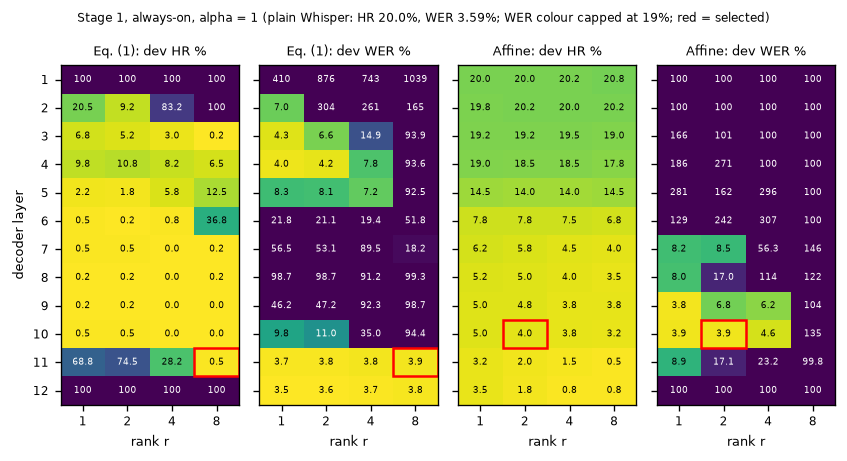

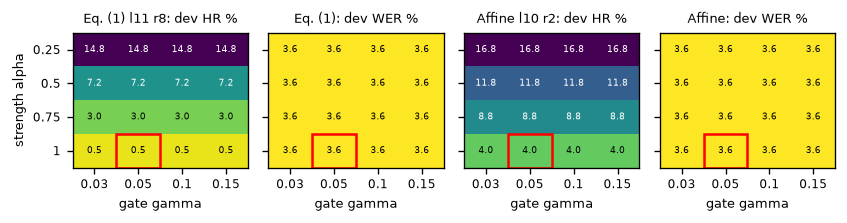

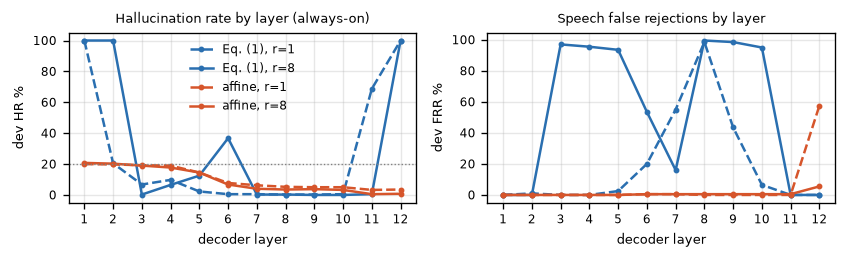

In [9]:
def heatmap(ax, pivot, title, vmin, vmax, mark=None):
    vals = pivot.values.astype(float)
    norm, cm = matplotlib.colors.Normalize(vmin, vmax), plt.get_cmap("viridis_r")
    ax.imshow(np.clip(vals, vmin, vmax), aspect="auto", cmap=cm, norm=norm)
    for i, j in np.ndindex(vals.shape):
        r, g, b, _ = cm(norm(min(vals[i, j], vmax)))
        ink = "black" if 0.299 * r + 0.587 * g + 0.114 * b > 0.45 else "white"   # readable on any cell colour
        v = vals[i, j]
        ax.text(j, i, f"{v:.1f}" if v < 100 else f"{v:.0f}", ha="center", va="center", color=ink, fontsize=5.5)
    ax.set_xticks(range(vals.shape[1]), [f"{c:g}" for c in pivot.columns])
    ax.set_yticks(range(vals.shape[0]), [f"{i:g}" for i in pivot.index])
    if mark is not None:
        i, j = list(pivot.index).index(mark[0]), list(pivot.columns).index(mark[1])
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="red", lw=1.5))
    ax.set_title(title)

wer_cap = base["WER"] + 15
fig, axs = plt.subplots(1, 4, figsize=(7.1, 0.22 * N_LAYERS + 1.2), sharey=True)
for k, (d, cfg, name) in enumerate(((df1, SELECTED, "Eq. (1)"), (df1a, AFFINE_SEL, "Affine"))):
    mark = (cfg.layer, cfg.rank)
    heatmap(axs[2 * k], d.pivot(index="layer", columns="rank", values="HR"), f"{name}: dev HR %", 0, 100, mark)
    heatmap(axs[2 * k + 1], d.pivot(index="layer", columns="rank", values="WER"), f"{name}: dev WER %", base["WER"], wer_cap, mark)
for a in axs:
    a.set_xlabel("rank r")
axs[0].set_ylabel("decoder layer")
fig.suptitle(f"Stage 1, always-on, alpha = 1 (plain Whisper: HR {base['HR']:.1f}%, WER {base['WER']:.2f}%; "
             f"WER colour capped at {wer_cap:.0f}%; red = selected)", fontsize=7)
plt.tight_layout()
save_fig("sweep_stage1")

fig, axs = plt.subplots(1, 4, figsize=(7.1, 1.9), sharey=True)
for k, (d, cfg, name) in enumerate(((df2, SELECTED, "Eq. (1)"), (df2a, AFFINE_SEL, "Affine"))):
    mark = (cfg.alpha, cfg.gamma)
    heatmap(axs[2 * k], d.pivot(index="alpha", columns="gamma", values="HR"), f"{name} l{cfg.layer} r{cfg.rank}: dev HR %",
            0, max(1.0, d.HR.max()), mark)
    heatmap(axs[2 * k + 1], d.pivot(index="alpha", columns="gamma", values="WER"), f"{name}: dev WER %", base["WER"], wer_cap, mark)
for a in axs:
    a.set_xlabel("gate gamma")
axs[0].set_ylabel("strength alpha")
plt.tight_layout()
save_fig("sweep_stage2")

fig, axs = plt.subplots(1, 2, figsize=(7.1, 2.2))
for d, name, col in ((df1, "Eq. (1)", "#2a6fb0"), (df1a, "affine", "#d6552b")):
    for r, ls in ((1, "--"), (8, "-")):
        s = d[d["rank"] == r].sort_values("layer")
        axs[0].plot(s.layer, s.HR, ls, color=col, marker="o", ms=2.5, label=f"{name}, r={r}")
        axs[1].plot(s.layer, s.FRR, ls, color=col, marker="o", ms=2.5)
axs[0].axhline(base["HR"], color="grey", lw=0.8, ls=":")
axs[0].set(xlabel="decoder layer", ylabel="dev HR %", title="Hallucination rate by layer (always-on)")
axs[1].set(xlabel="decoder layer", ylabel="dev FRR %", title="Speech false rejections by layer")
axs[0].legend(frameon=False)
for a in axs:
    a.set_xticks(SWEEP_LAYERS)
    a.grid(alpha=0.3)
plt.tight_layout()
save_fig("layer_profile")

## 9. Held-out evaluation

In [10]:
B_SEL, B_AFF = basis_for(SELECTED.layer, SELECTED.rank), basis_for(AFFINE_SEL.layer, AFFINE_SEL.rank)
ENGINES = {
    "original":      Engine("original", SELECTED, keep_raw=True),   # keep_raw: needed to rescore other thresholds
    "always":        Engine("always", replace(SELECTED, alpha=1.0), B_SEL),
    "gated":         Engine("gated", SELECTED, B_SEL),
    "gate_only":     Engine("gate_only", SELECTED),
    "always_affine": Engine("always", replace(AFFINE_SEL, alpha=1.0), B_AFF, center_for(AFFINE_SEL.layer)),
    "gated_affine":  Engine("gated", AFFINE_SEL, B_AFF, center_for(AFFINE_SEL.layer)),
}
if (AFFINE_SEL.layer, AFFINE_SEL.rank) != (SELECTED.layer, SELECTED.rank):   # affine at the Eq. (1) setting, for a direct comparison
    ENGINES[f"gated_affine_at_l{SELECTED.layer}r{SELECTED.rank}"] = Engine("gated", SELECTED, B_SEL, center_for(SELECTED.layer))
if PAPER_CFG.layer <= N_LAYERS and PAPER_CFG != SELECTED:
    B_PAPER = basis_for(PAPER_CFG.layer, PAPER_CFG.rank)
    ENGINES["always_paper"] = Engine("always", replace(PAPER_CFG, alpha=1.0), B_PAPER)
    ENGINES["gated_paper"] = Engine("gated", PAPER_CFG, B_PAPER)
    ENGINES["gated_paper_affine"] = Engine("gated", PAPER_CFG, B_PAPER, center_for(PAPER_CFG.layer))

EVAL_SETS = {
    "ESC-50 (folds 4-5)":     subsample(full["esc50_test"], LIMITS["esc50_test"]),
    "UrbanSound8K":           subsample(full["urban"], LIMITS["urban"]),
    "FSD50K (non-speech)":    subsample(full["fsd"], LIMITS["fsd"]),
    "LibriSpeech test-clean": subsample(full["test_clean"], LIMITS["test_clean"]),
    "LibriSpeech test-other": subsample(full["test_other"], LIMITS["test_other"]),
}
NONSPEECH, SPEECH = list(EVAL_SETS)[:3], list(EVAL_SETS)[3:]
MODES = list(ENGINES) + ["boh"]
safe = lambda s: "".join(c if c.isalnum() else "_" for c in s)
out_path = lambda mode, name: EVAL / mode / f"{safe(name)}.jsonl"

def apply_bag(results, bag):
    """Bag of Hallucinations: blank outputs that exactly match a frequent hallucinated phrase."""
    bag = set(bag)
    return [replace(r, text="") if normalize(r.text) in bag else r for r in results]

RECS = {m: {} for m in MODES}
for name, items in EVAL_SETS.items():
    todo = {m: e for m, e in ENGINES.items() if not out_path(m, name).exists()}   # only modes not saved yet
    if todo:
        res = run_many(items, todo, desc=name, ckpt=f"eval_{safe(name)}")
        for m in todo:
            save_jsonl(records(res[m], items), out_path(m, name))
        drop_ckpt(f"eval_{safe(name)}")
    if not out_path("boh", name).exists():
        orig = [Result(**{f: r[f] for f in Result.__dataclass_fields__}) for r in load_jsonl(out_path("original", name))]
        save_jsonl(records(apply_bag(orig, BAG), items), out_path("boh", name))
    for m in MODES:
        RECS[m][name] = load_jsonl(out_path(m, name))
    print(f"done: {name} ({len(items)} clips)  {(time.time() - T0) / 60:.1f} min")

SUMMARY = {m: {n: summarize(RECS[m][n]) for n in EVAL_SETS} for m in MODES}

ESC-50 (folds 4-5):   0%|          | 0/800 [00:00<?, ?clip/s]

done: ESC-50 (folds 4-5) (800 clips)  85.1 min


UrbanSound8K:   0%|          | 0/2000 [00:00<?, ?clip/s]

done: UrbanSound8K (2000 clips)  90.5 min


FSD50K (non-speech):   0%|          | 0/2000 [00:00<?, ?clip/s]

done: FSD50K (non-speech) (2000 clips)  101.9 min


LibriSpeech test-clean:   0%|          | 0/1000 [00:00<?, ?clip/s]

done: LibriSpeech test-clean (1000 clips)  108.6 min


LibriSpeech test-other:   0%|          | 0/1000 [00:00<?, ?clip/s]

done: LibriSpeech test-other (1000 clips)  115.8 min


## 10. Threshold baseline: plain Whisper with tau chosen on dev

In [11]:
dev_plain = {}
for nm, items in (("nonspeech", sw_ns), ("speech", sw_sp)):
    p = SW / f"dev_original_{nm}.jsonl"
    if not p.exists():
        res = run_many(items, {"original": Engine("original", PAPER_CFG, keep_raw=True)}, desc=f"dev plain {nm}", ckpt=f"dev_plain_{nm}")
        save_jsonl(records(res["original"], items), p)
        drop_ckpt(f"dev_plain_{nm}")
    dev_plain[nm] = load_jsonl(p)

# same rule as the projection sweep: lowest dev HR with dev WER within WER_TOL_PP (ties: lowest WER, then the largest tau)
dev_curve = pd.DataFrame([dict(tau=t, **plain_at(dev_plain, t)) for t in TAU_FINE]).set_index("tau")
dev_base = plain_at(dev_plain, TAU)
ok = dev_curve[dev_curve.WER <= dev_base["WER"] + WER_TOL_PP + 1e-9].reset_index()
best = ok.sort_values(["HR", "WER", "tau"], ascending=[True, True, False]).iloc[0]
TAU_DEV = float(best.tau)
ties = ok[(ok.HR == best.HR) & (ok.WER == best.WER)].tau.tolist()
(SW / "tau_selection.json").write_text(json.dumps(dict(tau_dev=TAU_DEV, ties=ties, dev_base=dev_base), indent=1))
save_table(dev_curve, "dev_tau_curve", show=False)
print(f"dev baseline (tau={TAU}): {dev_base}")
print(f"tau chosen on dev: {TAU_DEV}  (ties: {ties})")

held = pd.DataFrame([dict(tau=t, **plain_at(RECS["original"], t))
                     for t in sorted(set(TAU_FINE) | {0.005, 0.01, 0.7, 0.8, 0.9})]).set_index("tau")
save_table(held, "threshold_only_tradeoff", show=False)
display(held.loc[[t for t in (0.05, 0.1, 0.12, 0.15, TAU_DEV, 0.2, 0.3, 0.4, 0.5, 0.6) if t in held.index]].round(2))

RECS["plain_dev_tau"] = {n: rescore(RECS["original"][n], TAU_DEV) for n in EVAL_SETS}
SUMMARY["plain_dev_tau"] = {n: summarize(RECS["plain_dev_tau"][n]) for n in EVAL_SETS}
MODES.append("plain_dev_tau")

dev plain nonspeech:   0%|          | 0/400 [00:00<?, ?clip/s]

dev plain speech:   0%|          | 0/200 [00:00<?, ?clip/s]

dev baseline (tau=0.6): {'HR': np.float64(20.0), 'WER': np.float64(3.591635916359164), 'FRR': np.float64(0.0)}
tau chosen on dev: 0.17  (ties: [0.14, 0.15, 0.16, 0.17])


,HR,WER,FRR
tau,,,
0.05,0.07,16.87,17.80
0.10,0.37,7.74,5.10
0.12,0.46,6.77,3.10
0.15,0.71,6.18,2.00
0.17,0.87,5.93,1.35
0.20,1.26,5.64,0.65
0.30,3.12,5.48,0.10
0.40,8.39,5.47,0.00
0.50,16.64,5.47,0.00


## 11. Results tables

In [12]:
(EVAL / "summary.json").write_text(json.dumps(SUMMARY, indent=2))

def ci(s, k):
    lo, hi = s[k + "_ci95"]
    return f"{s[k]:.2f} [{lo:.2f}, {hi:.2f}]"

hr_tab = pd.DataFrame({n: {m: ci(SUMMARY[m][n], "HR") for m in MODES} for n in NONSPEECH})
sp_tab = pd.DataFrame({f"{n.split()[-1]} {k}": {m: SUMMARY[m][n][k] for m in MODES} for n in SPEECH for k in ("WER", "FRR")})
acc_tab = pd.DataFrame({f"{n.split()[-1]} WER (accepted only)": {m: SUMMARY[m][n]["WER_accepted"] for m in MODES} for n in SPEECH})
avg_tab = pd.DataFrame({m: averages(SUMMARY[m]) for m in MODES}).T.rename(columns=lambda c: f"avg {c}")
print("Hallucination rate % [95% bootstrap CI]")
save_table(hr_tab, "hallucination_rate")
print("Speech WER % / FRR %")
save_table(sp_tab, "speech_wer_frr")
save_table(acc_tab, "speech_wer_accepted_only", show=False)
print("Averages (HR over the 3 non-speech sets, WER / FRR over the 2 speech sets)")
save_table(avg_tab, "averages")

Hallucination rate % [95% bootstrap CI]


,ESC-50 (folds 4-5),UrbanSound8K,FSD50K (non-speech)
original,"26.12 [23.25, 29.12]","14.50 [13.00, 15.95]","44.60 [42.40, 46.70]"
always,"0.50 [0.12, 1.00]","1.50 [1.00, 2.00]","1.75 [1.20, 2.35]"
gated,"0.50 [0.12, 1.00]","1.50 [1.00, 2.00]","1.80 [1.20, 2.40]"
gate_only,"0.00 [0.00, 0.00]","0.00 [0.00, 0.00]","0.20 [0.05, 0.40]"
always_affine,"8.38 [6.62, 10.38]","6.60 [5.60, 7.70]","22.85 [21.00, 24.70]"
gated_affine,"8.38 [6.62, 10.38]","6.60 [5.60, 7.70]","22.85 [21.00, 24.70]"
gated_affine_at_l11r8,"1.00 [0.38, 1.75]","1.30 [0.85, 1.80]","1.80 [1.25, 2.40]"
always_paper,"1.38 [0.62, 2.25]","0.55 [0.25, 0.90]","7.10 [5.95, 8.30]"
gated_paper,"1.38 [0.62, 2.25]","0.65 [0.35, 1.00]","7.40 [6.25, 8.60]"
gated_paper_affine,"9.25 [7.38, 11.25]","7.00 [5.90, 8.05]","24.25 [22.40, 26.15]"


Speech WER % / FRR %


,test-clean WER,test-clean FRR,test-other WER,test-other FRR
original,3.31,0.0,7.63,0.0
always,3.37,0.2,10.25,3.3
gated,3.50,0.2,9.66,2.5
gate_only,13.07,14.9,20.68,20.7
always_affine,2.92,0.1,7.87,0.6
gated_affine,3.32,0.1,8.03,0.6
gated_affine_at_l11r8,13.03,0.9,20.65,5.4
always_paper,8.20,6.7,19.49,14.7
gated_paper,3.91,1.4,8.41,2.4
gated_paper_affine,3.31,0.1,7.65,0.1


Averages (HR over the 3 non-speech sets, WER / FRR over the 2 speech sets)


,avg HR,avg WER,avg FRR
original,28.41,5.47,0.00
always,1.25,6.81,1.75
gated,1.27,6.58,1.35
gate_only,0.07,16.87,17.80
always_affine,12.61,5.40,0.35
gated_affine,12.61,5.68,0.35
gated_affine_at_l11r8,1.37,16.84,3.15
always_paper,3.01,13.84,10.70
gated_paper,3.14,6.16,1.90
gated_paper_affine,13.50,5.48,0.10


### Comparison with the paper's numbers

In [13]:
PAPER = {  # (HR ESC-50, US8K, FSD50K), (WER clean, other), (FRR clean, other); arXiv:2609.04561 Tables 1-3
 "small":    {"original": ((23.50, 12.33, 21.35), (4.04, 8.38), (0.00, 0.00)), "always": ((1.50, 0.81, 6.68), (4.51, 11.48), (0.64, 4.86)),
              "gated": ((1.53, 0.84, 6.84), (4.37, 9.13), (0.41, 2.58))},
 "medium":   {"original": ((26.50, 14.52, 41.95), (3.66, 7.29), (0.03, 0.27)), "always": ((1.82, 0.62, 8.02), (6.40, 15.06), (5.68, 16.87)),
              "gated": ((2.75, 0.66, 8.78), (5.47, 11.68), (4.07, 9.97))},
 "large-v3": {"original": ((44.25, 76.08, 21.35), (4.06, 5.87), (0.04, 0.00)), "always": ((1.50, 0.87, 0.18), (12.95, 13.13), (10.50, 11.47)),
              "gated": ((8.38, 2.74, 1.15), (6.17, 6.57), (2.86, 1.40))},
}
COLS = ["HR ESC-50", "HR US8K", "HR FSD50K", "WER clean", "WER other", "FRR clean", "FRR other"]
if MODEL_NAME in PAPER and not SMOKE:
    ours = {"original": "original", "always": "always_paper", "gated": "gated_paper"}   # same operating point as the paper
    rows = []
    for m, om in ours.items():
        if om not in SUMMARY:
            continue
        s = SUMMARY[om]
        rows.append({"mode": m, "source": "paper", **dict(zip(COLS, sum(PAPER[MODEL_NAME][m], ())))})
        rows.append({"mode": m, "source": f"ours ({om})", **dict(zip(COLS, [s[n]["HR"] for n in NONSPEECH] +
                     [s[n]["WER"] for n in SPEECH] + [s[n]["FRR"] for n in SPEECH]))})
    save_table(pd.DataFrame(rows).set_index(["mode", "source"]), "comparison_with_paper")

HR ESC-50  HR US8K  HR FSD50K  WER clean  \
mode     source                                                          
original paper                    23.50    12.33      21.35       4.04   
         ours (original)          26.12    14.50      44.60       3.31   
always   paper                     1.50     0.81       6.68       4.51   
         ours (always_paper)       1.38     0.55       7.10       8.20   
gated    paper                     1.53     0.84       6.84       4.37   
         ours (gated_paper)        1.38     0.65       7.40       3.91   

                              WER other  FRR clean  FRR other  
mode     source                                                
original paper                     8.38       0.00       0.00  
         ours (original)           7.63       0.00       0.00  
always   paper                    11.48       0.64       4.86  
         ours (always_paper)      19.49       6.70      14.70  
gated    paper                     9.13       0.41       2.58  
         ours (gated_paper)        8.41       1.40       2.40

## 12. Figures

AUROC of p_ns, non-speech vs speech: {'original': 0.9991, 'always': 0.9983, 'gated': 0.9986, 'always_affine': 0.995, 'gated_affine': 0.9965, 'gated_affine_at_l11r8': 0.9947, 'always_paper': 0.9825, 'gated_paper': 0.9967, 'gated_paper_affine': 0.9983}


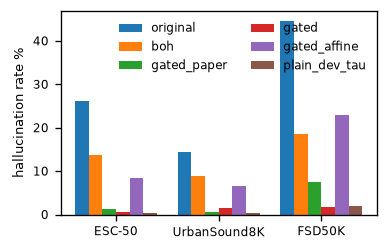

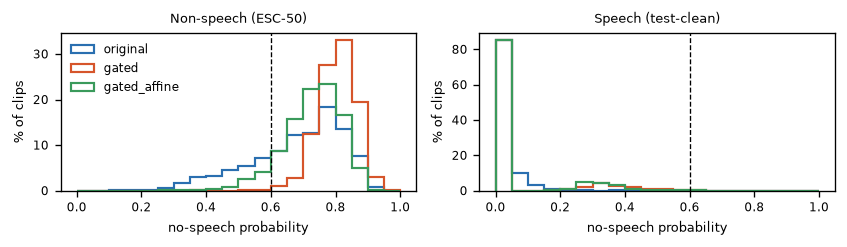

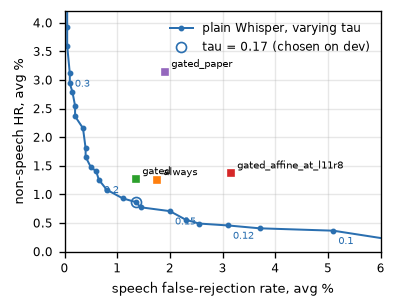

off the plot (FRR, HR): gate_only (17.8, 0.1); always_affine (0.3, 12.6); gated_affine (0.3, 12.6); always_paper (10.7, 3.0); gated_paper_affine (0.1, 13.5); boh (0.0, 13.7)


In [14]:
AUC = {}
for m in [m for m in MODES if m not in ("boh", "gate_only", "plain_dev_tau")]:
    pos = np.array([r["p_ns"] for n in NONSPEECH for r in RECS[m][n]])
    neg = np.array([r["p_ns"] for n in SPEECH for r in RECS[m][n]])
    ranks = rankdata(np.concatenate([pos, neg]))
    AUC[m] = float((ranks[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))
print("AUROC of p_ns, non-speech vs speech:", {k: round(v, 4) for k, v in AUC.items()})

# Hallucination rate per dataset
bars = [m for m in ("original", "boh", "gated_paper", "gated", "gated_affine", "plain_dev_tau") if m in MODES]
fig, ax = plt.subplots(figsize=(3.4, 2.2))
w = 0.8 / len(bars)
for i, m in enumerate(bars):
    ax.bar(np.arange(3) + i * w, [SUMMARY[m][n]["HR"] for n in NONSPEECH], w, label=m)
ax.set_xticks(np.arange(3) + w * (len(bars) - 1) / 2, ["ESC-50", "UrbanSound8K", "FSD50K"])
ax.set_ylabel("hallucination rate %")
ax.legend(frameon=False, ncol=2)
save_fig("hallucination_rate_by_dataset")

# No-speech probability before / after projection
fig, axs = plt.subplots(1, 2, figsize=(7.1, 2.1))
for ax, name, title in ((axs[0], NONSPEECH[0], "Non-speech (ESC-50)"), (axs[1], SPEECH[0], "Speech (test-clean)")):
    for m, c in (("original", "#2a6fb0"), ("gated", "#d6552b"), ("gated_affine", "#3a9a5b")):
        v = [r["p_ns"] for r in RECS[m][name]]
        ax.hist(v, bins=20, range=(0, 1), histtype="step", lw=1.3, color=c, label=m, weights=np.full(len(v), 100 / len(v)))
    ax.axvline(TAU, color="k", ls="--", lw=0.8)
    ax.set(title=title, xlabel="no-speech probability", ylabel="% of clips")
axs[0].legend(frameon=False)
plt.tight_layout()
save_fig("no_speech_probability")

# Trade-off: plain Whisper at every tau vs the projection settings (zoomed on the interesting region)
XMAX, YMAX = 6, 4.2
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.plot(held.FRR, held.HR, "-o", ms=2.5, color="#2a6fb0", lw=1.2, label="plain Whisper, varying tau")
for t in (0.1, 0.12, 0.15, 0.2, 0.3):
    if t in held.index:
        ax.annotate(f"{t:g}", (held.FRR[t], held.HR[t]), textcoords="offset points", xytext=(3, -8), fontsize=6, color="#2a6fb0")
ax.plot(held.FRR[TAU_DEV], held.HR[TAU_DEV], "o", ms=6, mfc="none", mec="#2a6fb0", label=f"tau = {TAU_DEV:g} (chosen on dev)")
off = []
PRETTY = {"always": "Eq. (1) always-on", "gated": "Eq. (1) gated", "gated_paper": "paper point, gated",
          "gated_affine_at_l11r8": "affine l11 r8, gated"}
NUDGE = {"gated": (0, 7, "center"), "always": (5, -9, "left"), "gated_affine_at_l11r8": (0, 7, "center")}   # label offset (points) and alignment
for m in [m for m in MODES if m not in ("original", "plain_dev_tau")]:
    a = averages(SUMMARY[m])
    if a["FRR"] <= XMAX and a["HR"] <= YMAX:
        ax.plot(a["FRR"], a["HR"], "s", ms=4)
        dx, dy, ha = NUDGE.get(m, (4, 3, "left"))
        ax.annotate(PRETTY.get(m, m), (a["FRR"], a["HR"]), textcoords="offset points", xytext=(dx, dy), fontsize=6, ha=ha)
    else:
        off.append(f"{m} ({a['FRR']:.1f}, {a['HR']:.1f})")
ax.set(xlim=(0, XMAX), ylim=(0, YMAX), xlabel="speech false-rejection rate, avg %", ylabel="non-speech HR, avg %")
ax.grid(alpha=0.3)
ax.legend(frameon=False, loc="upper right")
save_fig("tradeoff")
print("off the plot (FRR, HR):", "; ".join(off))

## 13. Paired significance tests against the threshold baseline

In [15]:
def mcnemar(a, b, key):
    """Exact McNemar test on per-clip 0/1 outcomes `key` of two methods on the same clips."""
    only_a = sum(bool(x[key]) and not bool(y[key]) for x, y in zip(a, b))
    only_b = sum(bool(y[key]) and not bool(x[key]) for x, y in zip(a, b))
    n = only_a + only_b
    return only_a, only_b, (binomtest(min(only_a, only_b), n, 0.5).pvalue if n else 1.0)

def paired_wer_diff(ma, mb, n_boot=2000, seed=0):
    """Mean over speech sets of WER(a) - WER(b), with a paired bootstrap 95% interval over utterances."""
    rng, diffs = np.random.default_rng(seed), []
    arr = {n: (np.array([r["errors"] for r in RECS[ma][n]]), np.array([r["errors"] for r in RECS[mb][n]]),
               np.array([r["ref_words"] for r in RECS[ma][n]])) for n in SPEECH}
    point = np.mean([100 * (ea.sum() - eb.sum()) / w.sum() for ea, eb, w in arr.values()])
    for _ in range(n_boot):
        d = []
        for ea, eb, w in arr.values():
            i = rng.integers(0, len(w), len(w))
            d.append(100 * (ea[i].sum() - eb[i].sum()) / w[i].sum())
        diffs.append(np.mean(d))
    return point, np.quantile(diffs, 0.025), np.quantile(diffs, 0.975)

def equal_hr_tau(mode):
    """Plain-Whisper tau (fine grid, held-out) whose average HR is closest to the mode's."""
    target = averages(SUMMARY[mode])["HR"]
    grid = held.loc[TAU_FINE]
    return float((grid.HR - target).abs().sort_values(kind="stable").index[0])

rows = []
for m in [m for m in ("gated", "gated_affine", "gated_paper", "gated_paper_affine") if m in MODES]:
    for label, tau in (("tau chosen on dev", TAU_DEV), ("tau at equal HR", equal_hr_tau(m))):
        ref = f"plain_tau_{tau:g}"
        if ref not in RECS:
            RECS[ref] = {n: rescore(RECS["original"][n], tau) for n in EVAL_SETS}
        rej = mcnemar([r for n in SPEECH for r in RECS[m][n]], [r for n in SPEECH for r in RECS[ref][n]], "rejected")
        hal = mcnemar([r for n in NONSPEECH for r in RECS[m][n]], [r for n in NONSPEECH for r in RECS[ref][n]], "text")
        d, lo, hi = paired_wer_diff(m, ref)
        rows.append({"projection": m, "plain Whisper": f"{label} ({tau:g})",
                     "rejections: only projection": rej[0], "rejections: only plain": rej[1], "rejections: p": rej[2],
                     "hallucinations: only projection": hal[0], "hallucinations: only plain": hal[1], "hallucinations: p": hal[2],
                     "avg WER diff": d, "95% CI low": lo, "95% CI high": hi})
paired = pd.DataFrame(rows).set_index(["projection", "plain Whisper"])
save_table(paired, "paired_tests")

rejections: only projection  \
projection         plain Whisper                                           
gated              tau chosen on dev (0.17)                           22   
                   tau at equal HR (0.2)                              24   
gated_affine       tau chosen on dev (0.17)                            4   
                   tau at equal HR (0.46)                              7   
gated_paper        tau chosen on dev (0.17)                           11   
                   tau at equal HR (0.3)                              36   
gated_paper_affine tau chosen on dev (0.17)                            0   
                   tau at equal HR (0.47)                              2   

                                             rejections: only plain  \
projection         plain Whisper                                      
gated              tau chosen on dev (0.17)                      22   
                   tau at equal HR (0.2)                         10   
gated_affine       tau chosen on dev (0.17)                      24   
                   tau at equal HR (0.46)                         0   
gated_paper        tau chosen on dev (0.17)                       0   
                   tau at equal HR (0.3)                          0   
gated_paper_affine tau chosen on dev (0.17)                      25   
                   tau at equal HR (0.47)                         0   

                                             rejections: p  \
projection         plain Whisper                             
gated              tau chosen on dev (0.17)           1.00   
                   tau at equal HR (0.2)              0.02   
gated_affine       tau chosen on dev (0.17)           0.00   
                   tau at equal HR (0.46)             0.02   
gated_paper        tau chosen on dev (0.17)           0.00   
                   tau at equal HR (0.3)              0.00   
gated_paper_affine tau chosen on dev (0.17)           0.00   
                   tau at equal HR (0.47)             0.50   

                                             hallucinations: only projection  \
projection         plain Whisper                                               
gated              tau chosen on dev (0.17)                               52   
                   tau at equal HR (0.2)                                  45   
gated_affine       tau chosen on dev (0.17)                              608   
                   tau at equal HR (0.46)                                192   
gated_paper        tau chosen on dev (0.17)                              126   
                   tau at equal HR (0.3)                                  91   
gated_paper_affine tau chosen on dev (0.17)                              650   
                   tau at equal HR (0.47)                                186   

                                             hallucinations: only plain  \
projection         plain Whisper                                          
gated              tau chosen on dev (0.17)                          31   
                   tau at equal HR (0.2)                             46   
gated_affine       tau chosen on dev (0.17)                           1   
                   tau at equal HR (0.46)                           169   
gated_paper        tau chosen on dev (0.17)                           3   
                   tau at equal HR (0.3)                             91   
gated_paper_affine tau chosen on dev (0.17)                           0   
                   tau at equal HR (0.47)                           177   

                                             hallucinations: p  avg WER diff  \
projection         plain Whisper                                               
gated              tau chosen on dev (0.17)               0.03          0.65   
                   tau at equal HR (0.2)                  1.00          0.94   
gated_affine       tau chosen on dev (0.17)               0.00         -0.25   


## 14. What the gate and the edit do

In [16]:
rows = []
for m, eng in ENGINES.items():
    if eng.mode not in ("gated", "always"):
        continue
    ns = [r for n in NONSPEECH for r in RECS[m][n]]
    row = {"mode": m, "gamma": eng.cfg.gamma if eng.mode == "gated" else None,
           "non-speech gate open %": 100 * np.mean([r["projected"] for r in ns])}
    for n in SPEECH:
        g, o, s = RECS[m][n], RECS["original"][n], n.split()[-1]
        opened = [i for i, r in enumerate(g) if r["projected"]]
        kept = [i for i in opened if not g[i]["rejected"]]
        rej = [i for i, r in enumerate(g) if r["rejected"]]
        row.update({f"{s}: gate open": len(opened), f"{s}: rejected of open": sum(g[i]["rejected"] for i in opened),
                    f"{s}: WER of projected+kept, plain": wer_of([o[i] for i in kept], "raw_errors"),
                    f"{s}: WER of projected+kept, edited": wer_of([g[i] for i in kept]),
                    f"{s}: words per rejected utt.": np.mean([o[i]["ref_words"] for i in rej]) if rej else np.nan,
                    f"{s}: words per utt.": np.mean([r["ref_words"] for r in o])})
    rows.append(row)
save_table(pd.DataFrame(rows).set_index("mode").T, "gate_analysis")

MUSIC = {"Music", "Musical_instrument", "Singing"}
fsd = NONSPEECH[2]
music = {m: {grp: 100 * np.mean([bool(r["text"]) for r in RECS[m][fsd] if bool(MUSIC & FSD_LABELS[Path(r["path"]).stem]) == grp] or [np.nan])
             for grp in (True, False)} for m in ("original", "gated", "gated_affine", "gated_paper", "boh") if m in MODES}
n_music = sum(bool(MUSIC & FSD_LABELS[Path(r["path"]).stem]) for r in RECS["original"][fsd])
print(f"FSD50K HR % for clips with / without a music label (n = {n_music} / {len(RECS['original'][fsd]) - n_music})")
save_table(pd.DataFrame(music).T.rename(columns={True: "music", False: "no music"}), "fsd50k_music")

mode,always,gated,always_affine,gated_affine,gated_affine_at_l11r8,always_paper,gated_paper,gated_paper_affine
gamma,NaN,0.05,NaN,0.05,0.05,NaN,0.15,0.15
non-speech gate open %,100.00,99.92,100.00,99.92,99.92,100.00,99.15,99.15
test-clean: gate open,1000.00,149.00,1000.00,149.00,149.00,1000.00,14.00,14.00
test-clean: rejected of open,2.00,2.00,1.00,1.00,9.00,67.00,14.00,1.00
"test-clean: WER of projected+kept, plain",3.30,4.55,3.30,4.52,4.56,3.28,0.00,4.00
"test-clean: WER of projected+kept, edited",3.18,4.65,2.91,4.66,99.64,3.24,0.00,4.80
test-clean: words per rejected utt.,20.00,20.00,2.00,2.00,12.22,15.40,9.07,2.00
test-clean: words per utt.,20.15,20.15,20.15,20.15,20.15,20.15,20.15,20.15
test-other: gate open,1000.00,207.00,1000.00,207.00,207.00,1000.00,26.00,26.00
test-other: rejected of open,33.00,25.00,6.00,6.00,54.00,147.00,24.00,1.00


FSD50K HR % for clips with / without a music label (n = 423 / 1577)


,music,no music
original,38.77,46.16
gated,2.60,1.59
gated_affine,17.02,24.41
gated_paper,2.84,8.62
boh,18.20,18.52


## 15. Why projecting the last decoder layer fails

In [17]:
# The SOT state after the last block goes straight to the final LayerNorm and the output embedding,
# so p_ns can be recomputed from the saved calibration states with and without the edit.
L = N_LAYERS
ln = copy.deepcopy(model.decoder.ln).float().cpu()
W = model.decoder.token_embedding.weight.detach().float().cpu()

def p_ns_of(h, chunk=256):
    return torch.cat([(ln(h[i:i + chunk]) @ W.T).softmax(-1)[:, tok.no_speech] for i in range(0, len(h), chunk)])

h = states[:, L - 1].float()
p0 = p_ns_of(h)
print(f"recomputed vs saved p_ns: max abs diff {float((p0 - torch.tensor(cal_df.p_ns.astype(float).values)).abs().max()):.4f}")
c = center_for(L)
rows = []
for r in SWEEP_RANKS:
    B = basis_for(L, r)
    p_zero = p_ns_of(h - (h @ B.T) @ B)
    p_aff = p_ns_of(h - ((h - c) @ B.T) @ B)
    rows.append({"rank": r, **{f"p_ns > tau, % ({k})": 100 * float((p > TAU).float().mean()) for k, p in
                               (("plain", p0), ("Eq. (1)", p_zero), ("affine", p_aff))},
                 **{f"median p_ns ({k})": float(p.median()) for k, p in (("plain", p0), ("Eq. (1)", p_zero), ("affine", p_aff))}})
save_table(pd.DataFrame(rows).set_index("rank"), "last_layer_p_ns")

b1 = basis_for(L, 1)[0]
coord = h @ b1
logp = torch.log(p0.clamp_min(1e-12))
last = dict(layer=L, coord_mean_hallucinated=float(coord[hall].mean()), coord_mean_empty=float(coord[~hall].mean()),
            corr_coord_log_p_ns=float(np.corrcoef(coord.numpy(), logp.numpy())[0, 1]))
(TAB / "last_layer_coordinate.json").write_text(json.dumps(last, indent=1))
print(last)

recomputed vs saved p_ns: max abs diff 0.0035


,"p_ns > tau, % (plain)","p_ns > tau, % (Eq. (1))","p_ns > tau, % (affine)",median p_ns (plain),median p_ns (Eq. (1)),median p_ns (affine)
rank,,,,,,
1,78.67,0.0,95.17,0.73,0.0,0.76
2,78.67,0.0,97.83,0.73,0.0,0.78
4,78.67,0.0,98.75,0.73,0.0,0.79
8,78.67,0.0,99.42,0.73,0.0,0.81


{'layer': 12, 'coord_mean_hallucinated': -79.63538360595703, 'coord_mean_empty': -91.63099670410156, 'corr_coord_log_p_ns': -0.7330714019610701}


## 16. Consistency checks on the paper's own numbers

In [18]:
T5 = {0.4: ((13.08, 5.77, 0.80), (2.89, 11.49, 10.91)), 0.5: ((20.42, 5.54, 0.35), (3.78, 9.90, 9.01)),   # medium,
      0.6: ((29.49, 5.48, 0.14), (5.09, 8.58, 7.03)), 0.7: ((42.75, 5.46, 0.09), (7.85, 7.28, 4.76))}      # (HR, WER, FRR) plain / +proj
FIG4 = {"BoH": (38.75, 75.41, 18.11), "WhisperX VAD": (4.13, 3.05, 8.55)}                                   # large-v3 HR
N_NS = (800, 8732, 8621)
mean = lambda v: float(np.mean(v))

def wilson(p, n, z=1.96):
    p /= 100
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return round(100 * (c - h), 2), round(100 * (c + h), 2)

checks = {
    "mean HR over models and sets": {m: round(mean([mean(PAPER[k][m][0]) for k in PAPER]), 2) for m in ("original", "always", "gated")},
    "mean HR per model": {k: {m: round(mean(v[0]), 2) for m, v in PAPER[k].items()} for k in PAPER},
    "medium: Table 5 (tau=0.6) vs Table 1, plain HR": (T5[0.6][0][0], round(mean(PAPER["medium"]["original"][0]), 2)),
    "medium: Table 5 (tau=0.6) vs Table 1, projected HR": (T5[0.6][1][0], round(mean(PAPER["medium"]["gated"][0]), 2)),
    "Fig. 4 mean HR": {k: round(mean(v), 2) for k, v in FIG4.items()},
    "large-v3 Wilson 95% CI": {m: [(h, wilson(h, n)) for h, n in zip(v, N_NS)] for m, v in
                               [("gated", PAPER["large-v3"]["gated"][0]), *FIG4.items()]},
    # if accepted transcripts were unchanged, dWER = share of reference words rejected; ratio to FRR < 1 means short utterances
    "implied rejected-word share / FRR": {f"{k} {m} {s}": round((100 * (PAPER[k][m][1][i] - PAPER[k]["original"][1][i]) /
                                                                 (100 - PAPER[k]["original"][1][i])) / PAPER[k][m][2][i], 2)
                                          for k in PAPER for m in ("always", "gated") for i, s in enumerate(("clean", "other"))},
}
(TAB / "paper_checks.json").write_text(json.dumps(checks, indent=1))
for k, v in checks.items():
    print(f"{k}: {v}")

mean HR over models and sets: {'original': 31.31, 'always': 2.44, 'gated': 3.74}
mean HR per model: {'small': {'original': 19.06, 'always': 3.0, 'gated': 3.07}, 'medium': {'original': 27.66, 'always': 3.49, 'gated': 4.06}, 'large-v3': {'original': 47.23, 'always': 0.85, 'gated': 4.09}}
medium: Table 5 (tau=0.6) vs Table 1, plain HR: (29.49, 27.66)
medium: Table 5 (tau=0.6) vs Table 1, projected HR: (5.09, 4.06)
Fig. 4 mean HR: {'BoH': 44.09, 'WhisperX VAD': 5.24}
large-v3 Wilson 95% CI: {'gated': [(8.38, (6.65, 10.5)), (2.74, (2.42, 3.1)), (1.15, (0.95, 1.4))], 'BoH': [(38.75, (35.44, 42.17)), (75.41, (74.5, 76.3)), (18.11, (17.31, 18.94))], 'WhisperX VAD': [(4.13, (2.96, 5.74)), (3.05, (2.71, 3.43)), (8.55, (7.98, 9.16))]}
implied rejected-word share / FRR: {'small always clean': 0.77, 'small always other': 0.7, 'small gated clean': 0.84, 'small gated other': 0.32, 'medium always clean': 0.5, 'medium always other': 0.5, 'medium gated clean': 0.46, 'medium gated other': 0.47, 'large-v3

## 17. Run information

In [19]:
run_info = dict(
    model=("tiny (smoke)" if SMOKE else MODEL_NAME), device=DEVICE, fp16=FP16, torch=torch.__version__,
    whisper=whisper.__version__, python=platform.python_version(),
    gpu=(torch.cuda.get_device_name(0) if DEVICE == "cuda" else None), seed=SEED, batch_size=BATCH_SIZE,
    limits=LIMITS, fsd_exclude=sorted(FSD_EXCLUDE), tau=TAU, wer_tolerance_pp=WER_TOL_PP,
    dataset_sizes={k: len(v) for k, v in full.items()}, eval_sizes={k: len(v) for k, v in EVAL_SETS.items()},
    calibration=dict(clips=len(cal_items), hallucinated=int(hall.sum()), empty=int((~hall).sum())),
    dev_baseline=base, paper_config=asdict(PAPER_CFG), selected=asdict(SELECTED), affine_selected=asdict(AFFINE_SEL),
    tau_dev=TAU_DEV, auroc=AUC, bag_of_hallucinations=[b[:40] for b in BAG],
    runtime_minutes=round((time.time() - T0) / 60, 1),
)
(RESULTS_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2))
print(json.dumps(run_info, indent=2))

{
  "model": "small",
  "device": "cuda",
  "fp16": true,
  "torch": "2.11.0+cu128",
  "whisper": "20250625",
  "python": "3.14.6",
  "gpu": "NVIDIA GeForce RTX 3050 6GB Laptop GPU",
  "seed": 0,
  "batch_size": 16,
  "limits": {
    "calib": null,
    "sweep_ns": 400,
    "sweep_speech": 200,
    "esc50_test": null,
    "urban": 2000,
    "fsd": 2000,
    "test_clean": 1000,
    "test_other": 1000
  },
  "fsd_exclude": [
    "Human_voice",
    "Speech"
  ],
  "tau": 0.6,
  "wer_tolerance_pp": 0.5,
  "dataset_sizes": {
    "esc50_cal": 1200,
    "esc50_test": 800,
    "urban": 8732,
    "fsd": 8598,
    "dev_clean": 2703,
    "test_clean": 2620,
    "test_other": 2939
  },
  "eval_sizes": {
    "ESC-50 (folds 4-5)": 800,
    "UrbanSound8K": 2000,
    "FSD50K (non-speech)": 2000,
    "LibriSpeech test-clean": 1000,
    "LibriSpeech test-other": 1000
  },
  "calibration": {
    "clips": 1200,
    "hallucinated": 256,
    "empty": 944
  },
  "dev_baseline": {
    "HR": 20.0,
    "WER": 3.